Price per Square Meter and Location Effects

Why do we need price_per_m2?


Suppose we compare two properties:

Property	Location	Area	Price
A            State X	300 m²	$300,000
B	         State Y	50 m²	$300,000


If we look only at:
price_usd

we'd say:

Both properties cost $300,000.

But that's not a very useful comparison.

Calculate:
Property A
300,000/300 = 1,000/m^2

Property B
300,000/50 = 6,000/m^2

Now we see:
Property A → $1,000/m²
Property B → $6,000/m²

Same total price.

Six times different in price per square meter.

That is why this feature is useful.

2. What are we trying to remove?

We're trying to reduce the obvious effect of:

more area -> more total price

Because if State A simply contains larger properties, its average total price might be higher even if the properties aren't actually more expensive per unit of space.

So we're asking:
Once we account for size, do different locations still have different levels of property value?

That's a much more interesting question.



## Feauture engineering

Raw total price (price_usd) is a useful metric but it is confounded by size. A $500,000 property could be a massive ranch house in a cheap area or a tiny penthouse in one of Mexico's most exclusive neighborhoods. To isolate the value of the location itself, we need a normalized metric.

## Price per Square Meter as a location-value proxy

            Price_per_m2 = price_usd/area_m2

This metric tells us the density of value: how much money is packed into each unit of space.

High price_per_m2 indicates:
A desirable, scarce location (city center, coastal resort)
Luxury finishes and amenities (pool, concierge, views)
Urban density where land is the scarce resource

Low price_per_m2 indicates:

Rural or suburban location with plentiful land
Basic finishes in a less competitive market

By analyzing "price_per_m2" rather than "price_usd", we partially "control for" size — making it much fairer to compare properties of different sizes and to compare different states.

In [ ]:
import pandas as pd

data_path = "../data/mexico-real-estate-combined-clean.csv"

data = pd.read_csv(data_path)

df = data.assign(price_per_m2 = lambda x: x["price_usd"]/x["area_m2"] )

print(df["price_per_m2"].describe())

## The range from min to max is the first indication that location creates enormous variation in value density.


count    1736.000000
mean      733.446495
std       429.350784
min       120.300752
25%       489.318571
50%       614.035088
75%       806.417259
max      3700.657895
Name: price_per_m2, dtype: float64


What is the "typical" cost of space in Mexico? Is the distribution symmetric, or does it have the same right skew as total price?

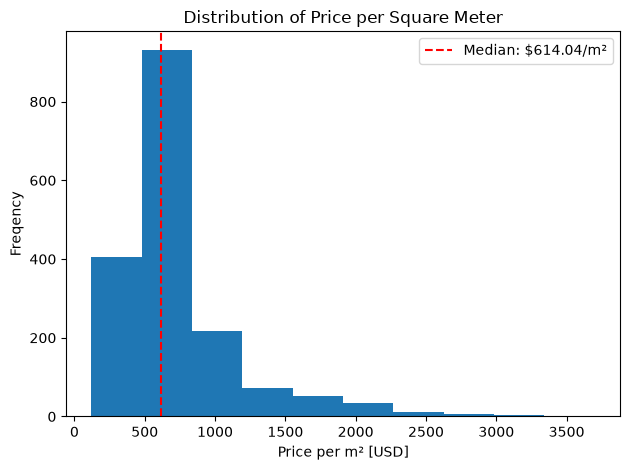

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.hist(df["price_per_m2"])

ax.set_title("Distribution of Price per Square Meter")
ax.set_xlabel("Price per m² [USD]")
ax.set_ylabel("Freqency")

median_price_per_m2 = df["price_per_m2"].median()

ax.axvline(median_price_per_m2, color='red', linestyle='--',label=f'Median: ${median_price_per_m2:.2f}/m²')
ax.legend()

plt.tight_layout()
plt.show()


Reading the price_per_m2 distribution

Shape: Right-skewed. Most Mexican properties fall in a standard affordability range — roughly 200–800/m² — with a long tail of high-value properties extending to 2,000/m² and beyond.

The median (red dashed line): The median sits to the left of the distribution's visual center, confirming the right skew. Properties above the median are more spread out (long right tail) than properties below it.

Why right skew persists even after normalizing for size:

Dividing by area reduces some of the skewness (large cheap houses are removed from the right tail in terms of total price). But the location effect creates new right-tail values: a 60 m² apartment in Mexico City's Polanco neighborhood might cost 3,000/m² — an extreme value that still pulls the distribution right.

Mean vs median for this metric:

For the same reason as with total price, the median is the more honest "typical" value for price_per_m2. The mean is inflated by a small number of luxury urban properties. When we compare states in §4, we will use the median as our primary comparison metric.